# Test du VAE

visualisation du vae image vers espace latent image

In [37]:
import os

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from numb_project.mnist_vae import VAE
from numb_project.utils import rotate_images
from numb_project.constants import VAE_CHECKPOINT_FILE, DEVICE

CKPT = os.path.join(os.path.dirname(VAE_CHECKPOINT_FILE), "mnist-20D.ckpt")
DEVICE = 'cuda'
vae = VAE.load_from_checkpoint(CKPT, map_location=DEVICE)

vae.eval()
vae.freeze()

VAE(
  (encoder): Encoder(
    (conv): Sequential(
      (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
    )
    (fc): Sequential(
      (0): Linear(in_features=3136, out_features=256, bias=True)
      (1): ReLU()
    )
    (fc_mu): Linear(in_features=256, out_features=20, bias=True)
    (fc_logvar): Linear(in_features=256, out_features=20, bias=True)
  )
  (decoder): Decoder(
    (fc): Sequential(
      (0): Linear(in_features=20, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=3136, bias=True)
      (3): ReLU()
    )
    (deconv): Sequential(
      (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    )
  )
)

In [38]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=True)

image_batch, _ = next(iter(test_loader))
image_batch = image_batch.to(DEVICE)

print("image_batch shape:", image_batch.shape)

image_batch shape: torch.Size([64, 1, 28, 28])


angle=  0°: MSE =0.00933
angle= 20°: MSE =0.00572
angle= 40°: MSE =0.00573
angle= 60°: MSE =0.00570
angle= 80°: MSE =0.00555
angle=100°: MSE =0.00556
angle=120°: MSE =0.00545
angle=140°: MSE =0.00549
angle=160°: MSE =0.00560
angle=180°: MSE =0.00901
angle=200°: MSE =0.00580
angle=220°: MSE =0.00559
angle=240°: MSE =0.00575
angle=260°: MSE =0.00556
angle=280°: MSE =0.00566
angle=300°: MSE =0.00564
angle=320°: MSE =0.00577
angle=340°: MSE =0.00569


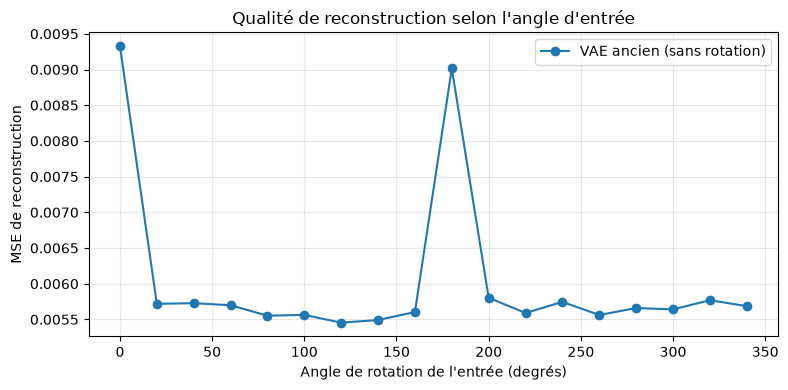

In [39]:
def reconstruct(vae: VAE, images: torch.Tensor) -> torch.Tensor:
    with torch.no_grad():
        mu, _ = vae.encoder(images)
        return vae.decoder(mu)


# --- MSE de reconstruction en fonction de l'angle de rotation de l'entrée ---
angles = list(range(0, 360, 20))
mse = []

for angle in angles:
    angle_deg = torch.full((image_batch.shape[0],), float(angle), device=image_batch.device)
    rotated = rotate_images(image_batch, angle_deg)

    recon = reconstruct(vae, rotated)

    mse.append(F.mse_loss(recon, rotated).item())
    print(f"angle={angle:>3}°: MSE ={mse[-1]:.5f}")

plt.figure(figsize=(8, 4))
plt.plot(angles, mse, marker="o", label="VAE ancien (sans rotation)")
plt.xlabel("Angle de rotation de l'entrée (degrés)")
plt.ylabel("MSE de reconstruction")
plt.title("Qualité de reconstruction selon l'angle d'entrée")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

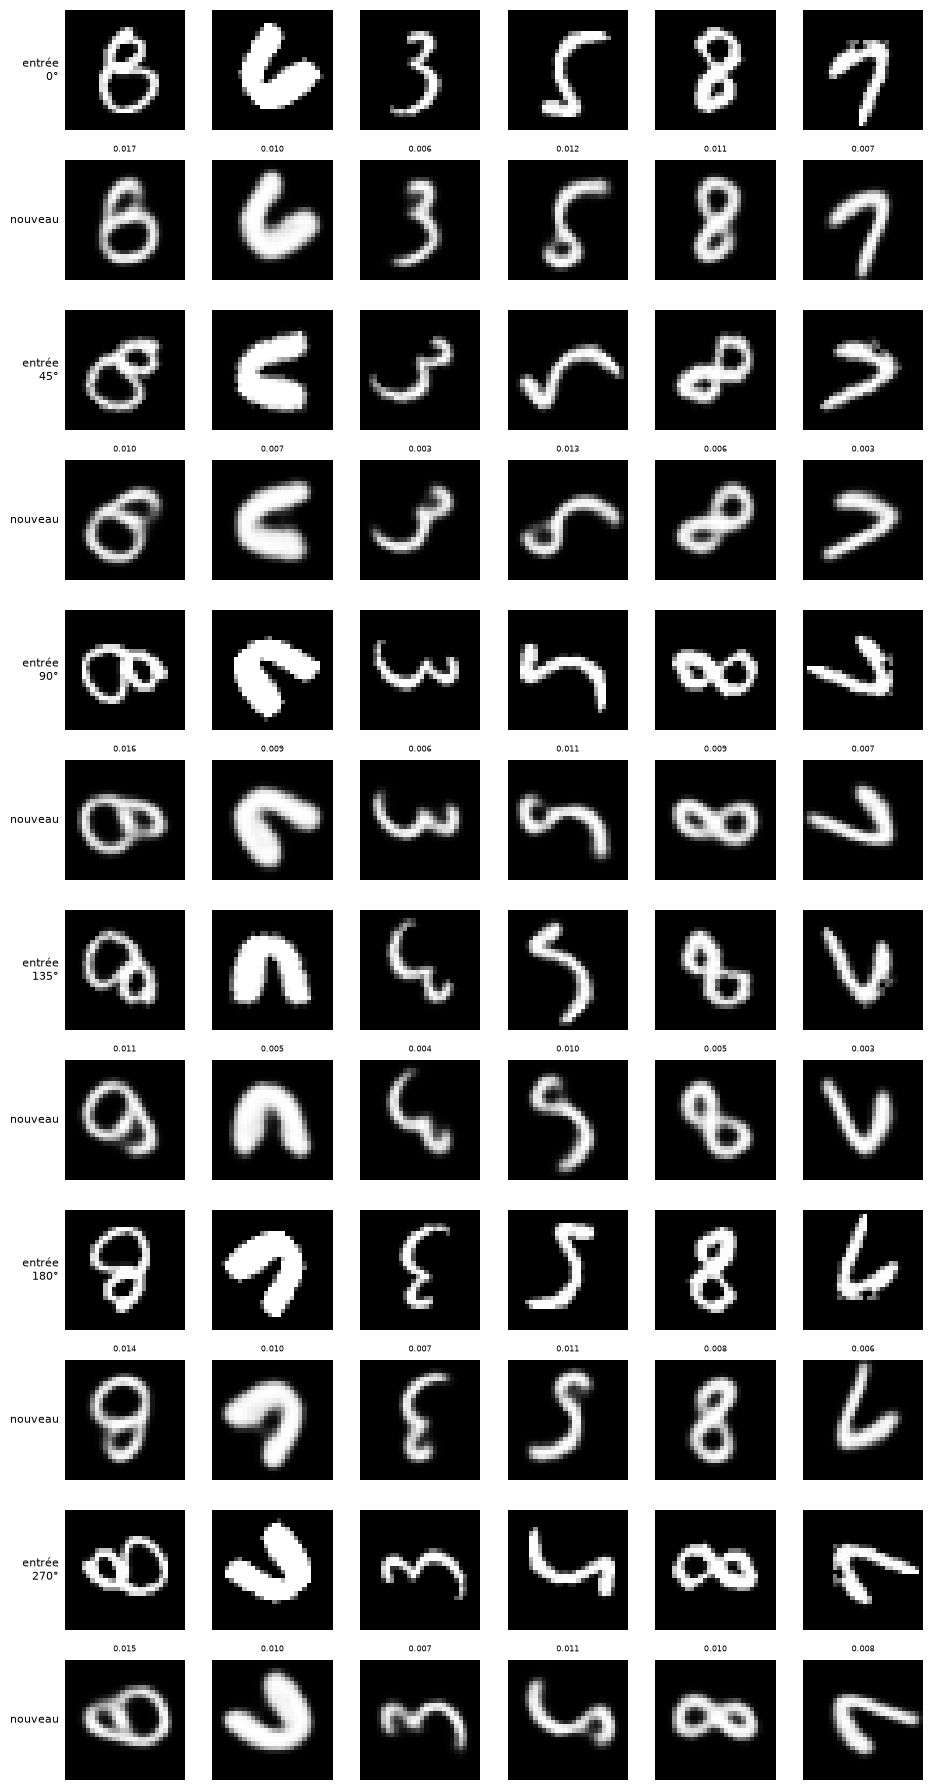

In [40]:
# --- Comparaison qualitative à quelques angles ---
# Pour chaque angle : l'image tournée en entrée, puis sa reconstruction par
# chaque VAE (avec le MSE par image affiché en titre), pour juger directement
# la qualité de chaque reconstruction face à ce qu'elle devait reproduire.
angles_to_show = [0, 45, 90, 135, 180, 270]
n_show = min(6, image_batch.shape[0])
n_groups = len(angles_to_show)
n_rows = 2 * n_groups  # par angle : entrée tournée / reconstruction ancien / reconstruction nouveau

fig, axes = plt.subplots(n_rows, n_show, figsize=(n_show * 1.6, 1.5 * n_rows))

def show_row(row: int, images: torch.Tensor, label: str, titles: list[str] | None = None) -> None:
    for i in range(n_show):
        ax = axes[row, i]
        ax.imshow(images[i, 0].detach().cpu().numpy(), cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if titles is not None:
            ax.set_title(titles[i], fontsize=6)
    axes[row, 0].set_ylabel(label, fontsize=8, rotation=0, ha="right", va="center")


row = 0
for angle in angles_to_show:
    angle_deg = torch.full((image_batch.shape[0],), float(angle), device=image_batch.device)
    rotated = rotate_images(image_batch, angle_deg)

    recon = reconstruct(vae, rotated)
    mse_per_img = [F.mse_loss(recon[i], rotated[i]).item() for i in range(n_show)]

    show_row(row, rotated, f"entrée\n{angle}°")
    show_row(row + 1, recon, "nouveau", titles=[f"{m:.3f}" for m in mse_per_img])

    row += 2

plt.tight_layout()
plt.show()

Dimensions actives : 20 / 20
dim  6: Var[mu]=1.0511  KL=2.150  actif
dim  9: Var[mu]=1.0268  KL=2.219  actif
dim  5: Var[mu]=1.0219  KL=2.312  actif
dim 19: Var[mu]=0.9675  KL=1.706  actif
dim 15: Var[mu]=0.9653  KL=1.429  actif
dim 11: Var[mu]=0.9639  KL=1.816  actif
dim  8: Var[mu]=0.9439  KL=1.429  actif
dim 18: Var[mu]=0.9399  KL=1.652  actif
dim 12: Var[mu]=0.9264  KL=1.473  actif
dim 13: Var[mu]=0.9232  KL=1.512  actif
dim 17: Var[mu]=0.9231  KL=1.581  actif
dim  3: Var[mu]=0.9149  KL=1.563  actif
dim  0: Var[mu]=0.9029  KL=1.264  actif
dim  1: Var[mu]=0.8857  KL=1.273  actif
dim 14: Var[mu]=0.8415  KL=1.030  actif
dim 10: Var[mu]=0.8099  KL=1.054  actif
dim  4: Var[mu]=0.7763  KL=0.870  actif
dim  7: Var[mu]=0.7656  KL=0.770  actif
dim 16: Var[mu]=0.7586  KL=0.841  actif
dim  2: Var[mu]=0.6779  KL=0.626  actif


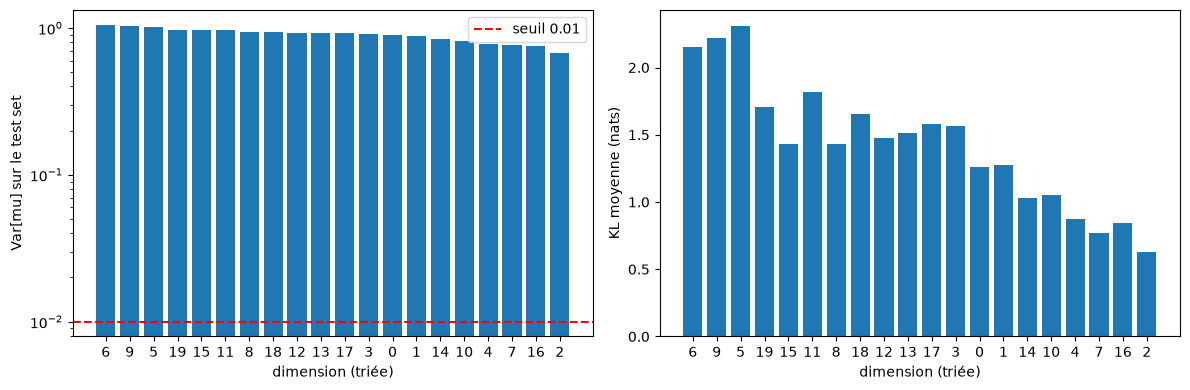

In [41]:
# --- Dimensions actives de l'espace latent ---
# Une dimension est "active" si son mu varie selon l'image (Var_x[mu_d] > 0.01).
# Une dimension morte a un mu ~ constant et un logvar ~ 0 (posterior = prior) :
# elle ne porte aucune information, sa KL moyenne est ~ 0.
generator = torch.Generator(device=DEVICE).manual_seed(0)  # angles fixes, résultat reproductible
eval_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

all_mu, all_logvar = [], []
with torch.no_grad():
    for images, _ in eval_loader:
        images = images.to(DEVICE)
        angle_deg = torch.rand(images.shape[0], device=DEVICE, generator=generator) * 360.0
        mu, logvar = vae.encoder(rotate_images(images, angle_deg))
        all_mu.append(mu)
        all_logvar.append(logvar)

all_mu = torch.cat(all_mu)
all_logvar = torch.cat(all_logvar)

mu_var = all_mu.var(dim=0).cpu()
kl_per_dim = (-0.5 * (1 + all_logvar - all_mu.pow(2) - all_logvar.exp())).mean(dim=0).cpu()

threshold = 0.01
active = mu_var > threshold
print(f"Dimensions actives : {active.sum().item()} / {len(mu_var)}")
for d in torch.argsort(mu_var, descending=True).tolist():
    print(f"dim {d:>2}: Var[mu]={mu_var[d]:.4f}  KL={kl_per_dim[d]:.3f}  {'actif' if active[d] else 'mort'}")

order = torch.argsort(mu_var, descending=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(len(mu_var)), mu_var[order], color=["C0" if a else "C7" for a in active[order]])
axes[0].axhline(threshold, color="red", linestyle="--", label=f"seuil {threshold}")
axes[0].set_yscale("log")
axes[0].set_xticks(range(len(mu_var)), order.tolist())
axes[0].set_xlabel("dimension (triée)")
axes[0].set_ylabel("Var[mu] sur le test set")
axes[0].legend()
axes[1].bar(range(len(kl_per_dim)), kl_per_dim[order], color=["C0" if a else "C7" for a in active[order]])
axes[1].set_xticks(range(len(kl_per_dim)), order.tolist())
axes[1].set_xlabel("dimension (triée)")
axes[1].set_ylabel("KL moyenne (nats)")
plt.tight_layout()
plt.show()

sonde linéaire: erreur moyenne =  44.9°, médiane =  33.5°, < 15° pour 25.0% des images
sonde MLP     : erreur moyenne =  15.2°, médiane =   9.6°, < 15° pour 69.1% des images
(hasard : erreur moyenne de 90°)

Erreur médiane par chiffre :
  0: linéaire  43.9°  MLP  10.3°
  1: linéaire  32.5°  MLP   7.1°
  2: linéaire  33.4°  MLP  12.7°
  3: linéaire  54.3°  MLP  10.2°
  4: linéaire  37.2°  MLP  10.1°
  5: linéaire  39.3°  MLP  11.4°
  6: linéaire  50.1°  MLP  10.7°
  7: linéaire  20.5°  MLP   8.3°
  8: linéaire  29.4°  MLP   9.4°
  9: linéaire  19.7°  MLP   8.7°


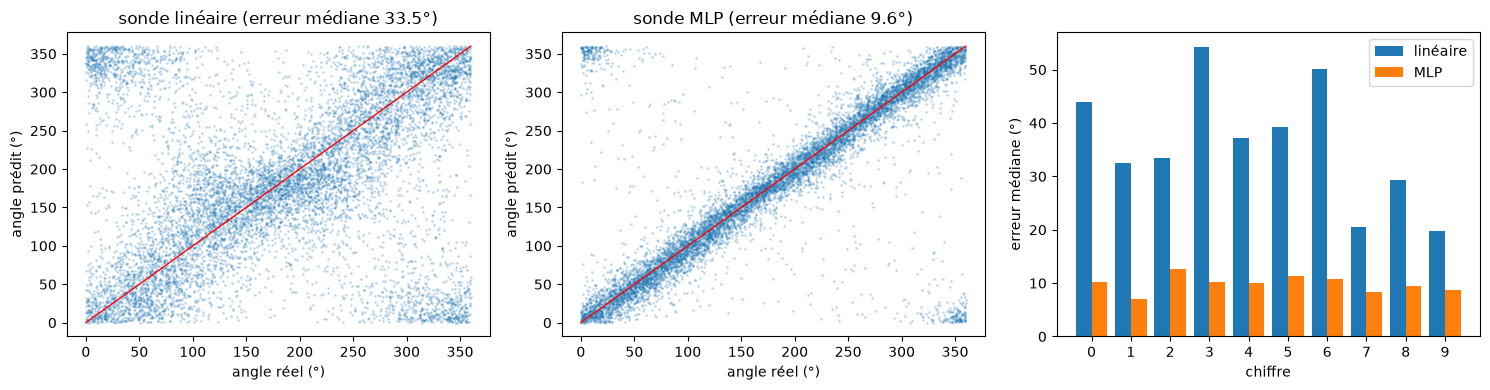

In [42]:
# --- Sonde d'angle : l'angle de rotation est-il encodé dans mu ? ---
# On encode des images tournées d'un angle connu, puis on apprend à prédire
# (cos, sin) de l'angle à partir de mu : (cos, sin) évite la discontinuité 0°/360°.
#  - sonde linéaire : l'angle est-il lisible "directement" dans mu ?
#  - sonde MLP      : l'angle est-il présent, même de façon non linéaire ?
# La sonde est apprise sur le train set et évaluée sur le test set.
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor


def encode_with_angles(dataset, n_images: int, seed: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    loader = DataLoader(torch.utils.data.Subset(dataset, range(n_images)), batch_size=512, shuffle=False)
    all_mu, all_angles, all_labels = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            angle_deg = torch.rand(images.shape[0], device=DEVICE, generator=generator) * 360.0
            mu, _ = vae.encoder(rotate_images(images, angle_deg))
            all_mu.append(mu.cpu())
            all_angles.append(angle_deg.cpu())
            all_labels.append(labels)
    return torch.cat(all_mu).numpy(), torch.cat(all_angles).numpy(), torch.cat(all_labels).numpy()


def angle_error_deg(pred_cos_sin: np.ndarray, true_angle_deg: np.ndarray) -> np.ndarray:
    pred_angle = np.degrees(np.arctan2(pred_cos_sin[:, 1], pred_cos_sin[:, 0]))
    diff = (pred_angle - true_angle_deg + 180.0) % 360.0 - 180.0
    return np.abs(diff)


train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
mu_train, angle_train, _ = encode_with_angles(train_dataset, n_images=20000, seed=0)
mu_test, angle_test, label_test = encode_with_angles(test_dataset, n_images=len(test_dataset), seed=1)

def to_cos_sin(angle_deg: np.ndarray) -> np.ndarray:
    return np.stack([np.cos(np.radians(angle_deg)), np.sin(np.radians(angle_deg))], axis=1)

probes = {
    "linéaire": Ridge(alpha=1.0),
    "MLP": MLPRegressor(hidden_layer_sizes=(256, 256), max_iter=200, early_stopping=True, random_state=0),
}
errors = {}
for name, probe in probes.items():
    probe.fit(mu_train, to_cos_sin(angle_train))
    errors[name] = angle_error_deg(probe.predict(mu_test), angle_test)
    print(f"sonde {name:<8}: erreur moyenne = {errors[name].mean():5.1f}°, médiane = {np.median(errors[name]):5.1f}°, "
          f"< 15° pour {100 * (errors[name] < 15).mean():4.1f}% des images")
print("(hasard : erreur moyenne de 90°)")

# Erreur par chiffre : 0, 1 et 8 sont presque symétriques par rotation de 180°,
# leur angle peut être ambigu même pour un encodeur parfait.
print("\nErreur médiane par chiffre :")
for digit in range(10):
    mask = label_test == digit
    print(f"  {digit}: " + "  ".join(f"{name} {np.median(err[mask]):5.1f}°" for name, err in errors.items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, err) in zip(axes[:2], errors.items()):
    pred_cos_sin = probes[name].predict(mu_test)
    pred_angle = np.degrees(np.arctan2(pred_cos_sin[:, 1], pred_cos_sin[:, 0])) % 360.0
    ax.scatter(angle_test, pred_angle, s=1, alpha=0.2)
    ax.plot([0, 360], [0, 360], color="red", linewidth=1)
    ax.set_xlabel("angle réel (°)")
    ax.set_ylabel("angle prédit (°)")
    ax.set_title(f"sonde {name} (erreur médiane {np.median(err):.1f}°)")
width = 0.4
for i, (name, err) in enumerate(errors.items()):
    axes[2].bar(np.arange(10) + (i - 0.5) * width, [np.median(err[label_test == d]) for d in range(10)], width, label=name)
axes[2].set_xticks(range(10))
axes[2].set_xlabel("chiffre")
axes[2].set_ylabel("erreur médiane (°)")
axes[2].legend()
plt.tight_layout()
plt.show()